In [1]:
import pandas as pd
import numpy as np
import scipy.stats as stats
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
db = pd.read_csv("Diabetes.csv")

In [3]:
db.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72.0,35,169.5,33.6,0.627,50,1
1,1,85,66.0,29,102.5,26.6,0.351,31,0
2,8,183,64.0,32,169.5,23.3,0.672,32,1
3,1,89,66.0,23,94.0,28.1,0.167,21,0
4,0,137,40.0,35,168.0,43.1,2.288,33,1


In [4]:
#Select the variable for Bootstrap
glucose = db["Glucose"].dropna()

print("Number of observations:", len(glucose))
print("Original sample mean:", glucose.mean())

Number of observations: 768
Original sample mean: 121.67708333333333


In [5]:
#Generate Bootstrap Samples
np.random.seed(42)

n_bootstrap = 10000
bootstrap_means = []

for i in range(n_bootstrap):
    bootstrap_sample = np.random.choice(glucose, size=len(glucose), replace=True)
    bootstrap_means.append(np.mean(bootstrap_sample))

bootstrap_means = np.array(bootstrap_means)

print("Number of bootstrap samples:", len(bootstrap_means))
print("Mean of bootstrap distribution:", bootstrap_means.mean())

Number of bootstrap samples: 10000
Mean of bootstrap distribution: 121.68362473958332


In [6]:
#Construct the 95% Bootstrap Confidence Interval
lower_ci = np.percentile(bootstrap_means, 2.5)
upper_ci = np.percentile(bootstrap_means, 97.5)

print("95% Bootstrap Confidence Interval:")
print("Lower Limit:", lower_ci)
print("Upper Limit:", upper_ci)

95% Bootstrap Confidence Interval:
Lower Limit: 119.54016927083333
Upper Limit: 123.8138671875


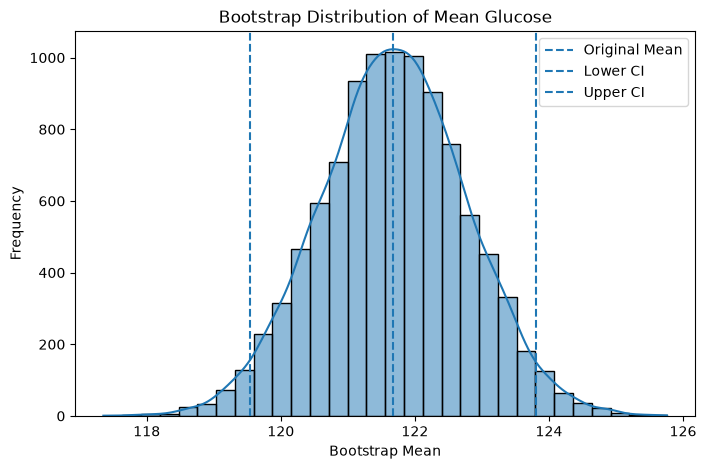

In [7]:
#Bootstrap Distribution
plt.figure(figsize=(8, 5))

sns.histplot(bootstrap_means, bins=30, kde=True)

plt.axvline(glucose.mean(), linestyle="--", label="Original Mean")
plt.axvline(lower_ci, linestyle="--", label="Lower CI")
plt.axvline(upper_ci, linestyle="--", label="Upper CI")

plt.title("Bootstrap Distribution of Mean Glucose")
plt.xlabel("Bootstrap Mean")
plt.ylabel("Frequency")
plt.legend()

plt.show()

In [8]:
#Divide the Data into Two Groups
#Outcome = 1 → Diabetic
#Outcome = 0 → Non-diabetic
diabetic = db[db["Outcome"] == 1]["Glucose"].dropna()
non_diabetic = db[db["Outcome"] == 0]["Glucose"].dropna()

print("Number of diabetic patients:", len(diabetic))
print("Number of non-diabetic patients:", len(non_diabetic))

print("\nMean Glucose - Diabetic:", diabetic.mean())
print("Mean Glucose - Non-diabetic:", non_diabetic.mean())

Number of diabetic patients: 268
Number of non-diabetic patients: 500

Mean Glucose - Diabetic: 142.30223880597015
Mean Glucose - Non-diabetic: 110.622


In [9]:
#Observed Difference
#Difference = Mean Glucose (Diabetic) − Mean Glucose (Non-diabetic)
observed_difference = diabetic.mean() - non_diabetic.mean()

print("Observed Difference in Mean Glucose:", observed_difference)

Observed Difference in Mean Glucose: 31.68023880597015


In [10]:
#Permutation Distribution
np.random.seed(42)

n_permutations = 10000
permutation_differences = []

glucose_values = db["Glucose"].dropna().values
outcome_labels = db.loc[db["Glucose"].notna(), "Outcome"].values

for i in range(n_permutations):
    shuffled_labels = np.random.permutation(outcome_labels)

    perm_diabetic = glucose_values[shuffled_labels == 1]
    perm_non_diabetic = glucose_values[shuffled_labels == 0]

    difference = perm_diabetic.mean() - perm_non_diabetic.mean()
    permutation_differences.append(difference)

permutation_differences = np.array(permutation_differences)

print("Number of permutations:", len(permutation_differences))
print("Mean of permutation distribution:", permutation_differences.mean())

Number of permutations: 10000
Mean of permutation distribution: -0.008678017910447713


In [11]:
#Permutation p-value
id="r7m2px"
permutation_p_value = np.mean(
    np.abs(permutation_differences) >= np.abs(observed_difference)
)

print("Observed Difference:", observed_difference)
print("Permutation p-value:", permutation_p_value)

Observed Difference: 31.68023880597015
Permutation p-value: 0.0


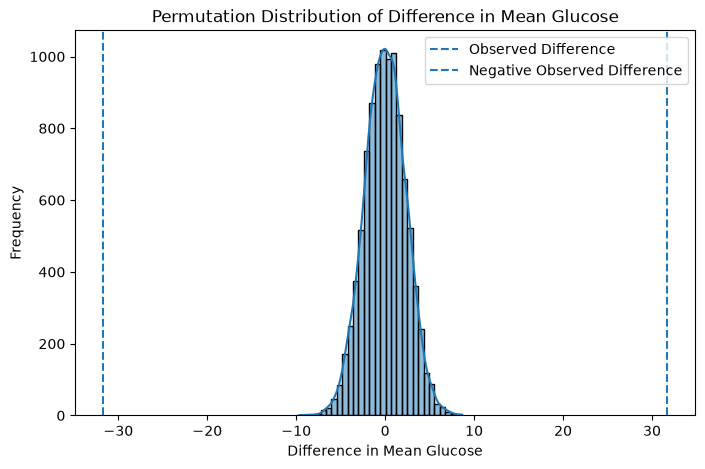

In [12]:
#Permutation Distribution
plt.figure(figsize=(8, 5))

sns.histplot(permutation_differences, bins=30, kde=True)

plt.axvline(
    observed_difference,
    linestyle="--",
    label="Observed Difference"
)

plt.axvline(
    -observed_difference,
    linestyle="--",
    label="Negative Observed Difference"
)

plt.title("Permutation Distribution of Difference in Mean Glucose")
plt.xlabel("Difference in Mean Glucose")
plt.ylabel("Frequency")
plt.legend()

plt.show()